# 14 · Five port cities, four tide-gauge proxies

**Time:** 50 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** Audit city-to-gauge distances, compare scenario distributions, and preserve uncertainty in a map narrative.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=14_ar6_port_cities.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


> **Data identity:** real modeled projections, not observations. AR6 v20210809; workflow `wf_1e`; 20,000 Monte Carlo samples at each decade from 2020 to 2100. Source values are millimetres of relative sea-level change from the 1995–2014 reference period; plots convert them to metres. Background land motion is included.

> **Interpretation:** a workflow distribution is not the assessed IPCC probability box (p-box). The source FAQ says `wf_1e` does not preserve time correlations: do not calculate rates, sample trajectories, or first-crossing dates. The exercise compares distributions at specified years. These data alone cannot map inundation or rank port vulnerability.

![From archive chunks to projection distributions, with flood-risk evidence kept separate](assets/ar6-workflow.svg)

In [2]:
from ar6 import load_ar6, coverage_map, coastline, gauge_summary, summary_sql, export_summary
p, years, gauge_m, grid_m = load_ar6()
print('Samples: scenario, sample, year, unique gauge =', gauge_m.shape)
print('Nearest defined grid samples: sample, year, city =', grid_m.shape)

Samples: scenario, sample, year, unique gauge = (2, 20000, 9, 4)
Nearest defined grid samples: sample, year, city = (20000, 9, 5)


## 1. Locate the evidence before plotting a projection

City reference points are rounded geographic anchors, not surveyed ports or administrative boundaries. The preparation script finds the nearest available gauge **projection location**, using great-circle distance; it does not retrieve an observed tide-gauge time series.

Both Abidjan and Lagos map to **Takoradi, Ghana** in this archive. Displaying that series twice does not provide two independent local projections. Do not label it “measured Lagos sea level.” Bangkok uses Fort Phrachula Chomklao, Ho Chi Minh City uses Vung Tau, and Manila uses the Manila site. The next lesson uses grid windows to expose the proxy problem.

Abidjan            -> TAKORADI                 ID  331 | 256.1 km
Lagos              -> TAKORADI                 ID  331 | 594.9 km
Bangkok            -> FORT_PHRACHULA_CHOMKLAO  ID  444 | 24.9 km
Ho Chi Minh City   -> VUNGTAU                  ID 1495 | 64.3 km
Manila             -> MANILA                   ID  145 | 2.5 km


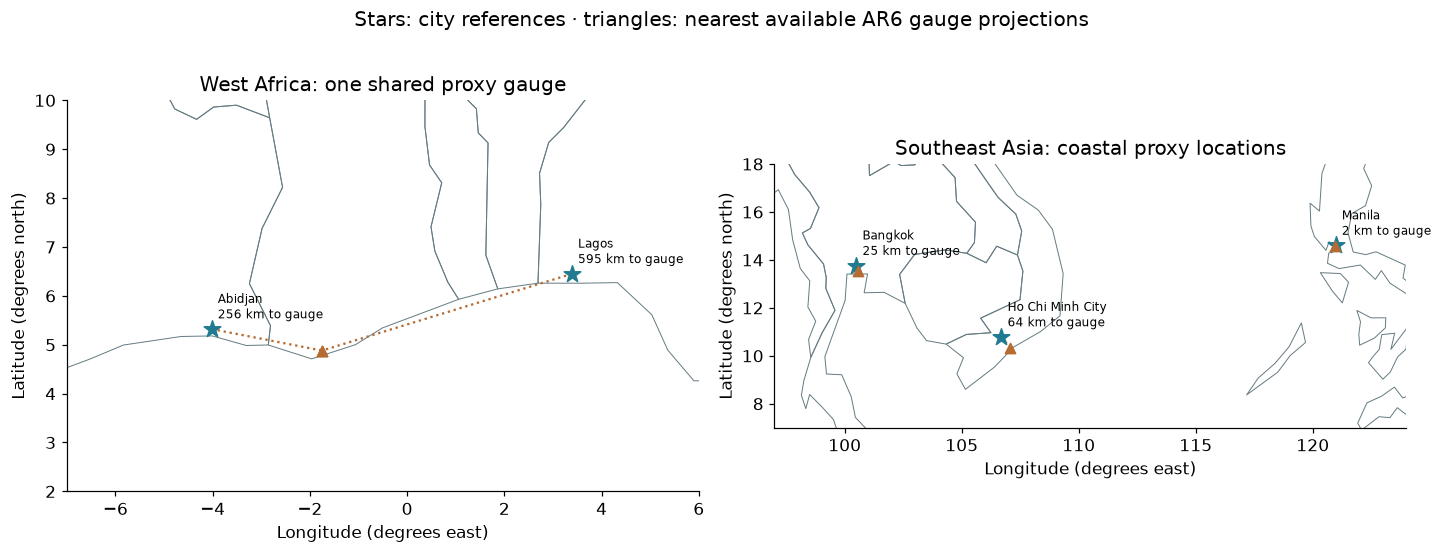

In [3]:
for c in p['cities']:
    g=p['gauges'][c['gauge_column']]
    print(f"{c['name']:18} -> {g['name']:24} ID {g['id']:4} | {c['gauge_distance_km']:.1f} km")
coverage_map(p);plt.show()

## 2. Read scenario spread and sample spread separately

Choose SSP1-2.6 (lower emissions) and SSP5-8.5 (higher emissions) **conditional scenarios**, not assigned likelihoods. At each decade compute the 17th, 50th, and 83rd percentiles of all 20,000 samples. The shaded interval is this workflow's central 66% sample interval; it is not a confidence interval on the median and not the IPCC assessed likely p-box range.

Lines connect per-year medians as visual guides. They do not track any one Monte Carlo realization. All panels share the same vertical scale; African panels deliberately reveal the shared gauge.

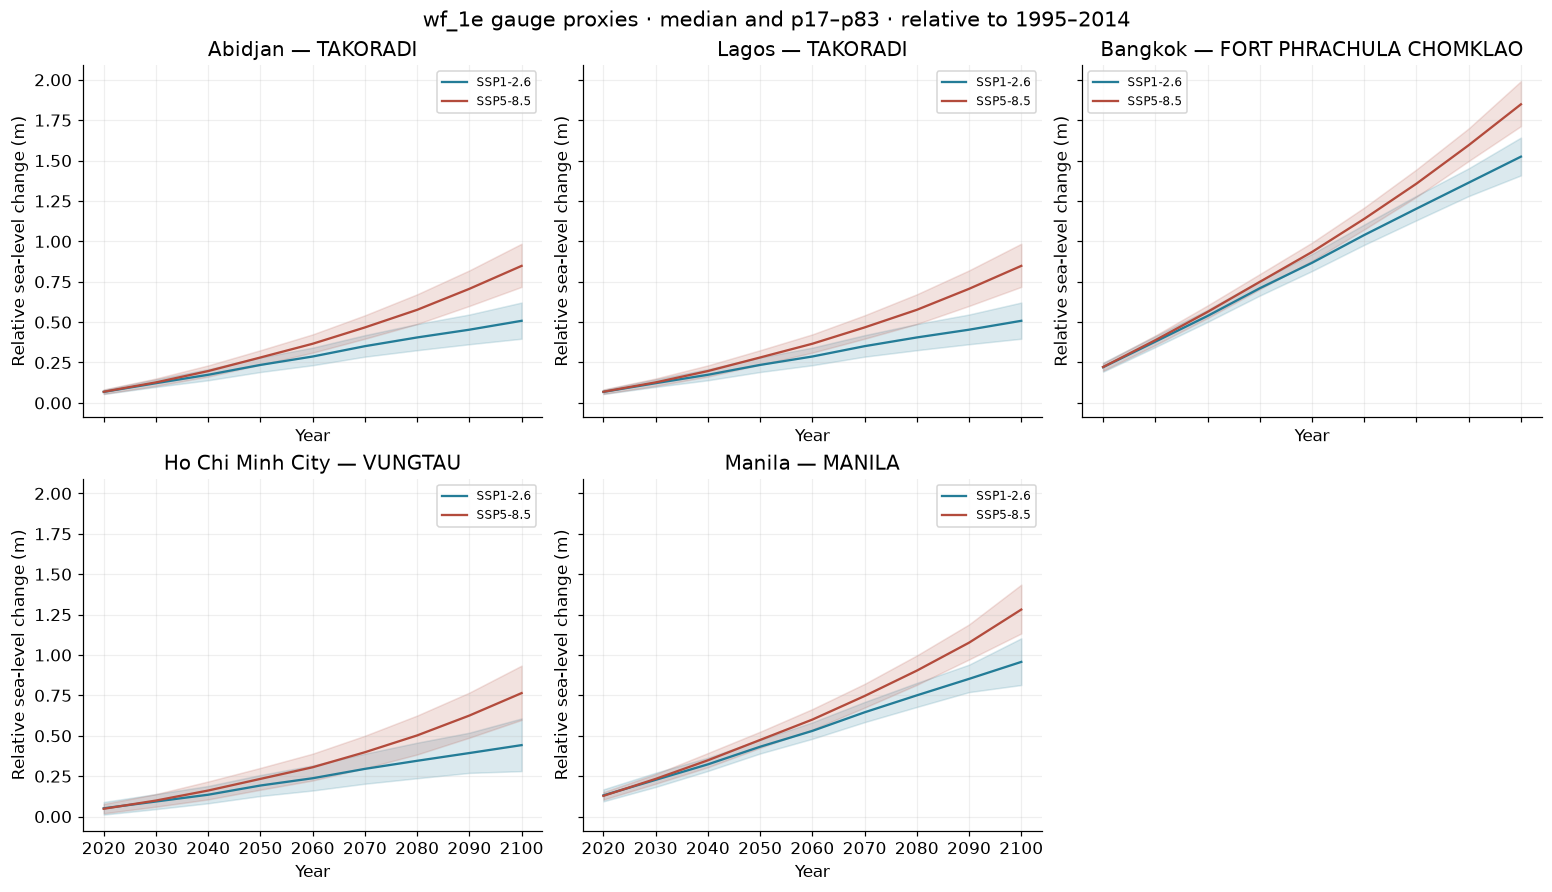

In [4]:
fig,axes=plt.subplots(2,3,figsize=(14,8),sharex=True,sharey=True,constrained_layout=True)
q=np.quantile(gauge_m,[.17,.5,.83],axis=1,method='linear')
for ax,c in zip(axes.flat,p['cities']):
    g=c['gauge_column']
    for s,(label,color) in enumerate([('SSP1-2.6','#237c97'),('SSP5-8.5','#b34b3c')]):
        ax.fill_between(years,q[0,s,:,g],q[2,s,:,g],color=color,alpha=.16)
        ax.plot(years,q[1,s,:,g],color=color,label=label)
    ax.set(title=c['name']+' — '+p['gauges'][g]['name'].replace('_',' '),xlabel='Year',ylabel='Relative sea-level change (m)')
    ax.grid(alpha=.2);ax.legend(fontsize=8)
axes.flat[-1].axis('off')
fig.suptitle('wf_1e gauge proxies · median and p17–p83 · relative to 1995–2014',fontsize=14)
plt.show()

## 3. Verify one statistic independently

The source is in millimetres. Conversion to metres divides by 1,000; do it exactly once. Each year is a distribution of possible levels. Inspect an empirical cumulative distribution at 2100 for the Manila gauge.

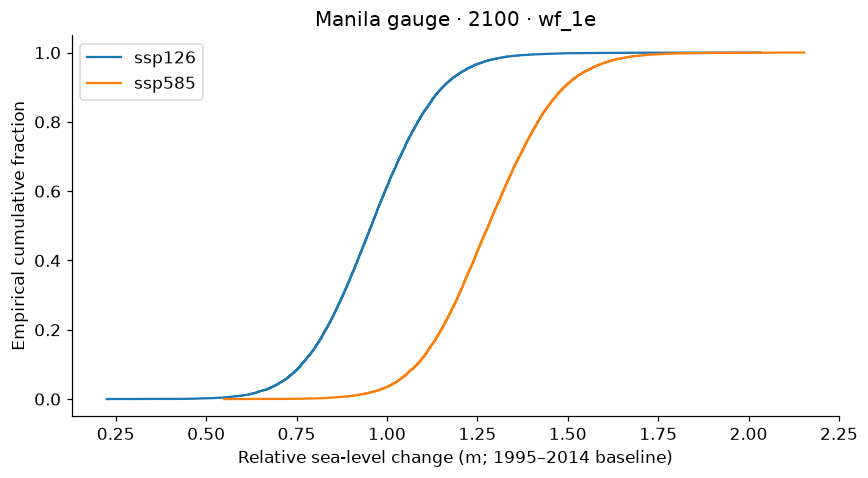

In [5]:
city=p['cities'][-1]; g=city['gauge_column']; t=int(np.where(years==2100)[0][0])
fig,ax=plt.subplots()
for s,label in enumerate(p['gauge_scenarios']):
    v=np.sort(gauge_m[s,:,t,g])
    ax.plot(v,np.arange(1,len(v)+1)/len(v),label=label)
ax.set(xlabel='Relative sea-level change (m; 1995–2014 baseline)',ylabel='Empirical cumulative fraction',title='Manila gauge · 2100 · wf_1e')
ax.legend();plt.show()
assert np.isclose(np.median(gauge_m[1,:,t,g]),q[1,1,t,g])

## 4. Turn the distributions into a SQL view

The 72 rows below represent **four unique gauges × two scenarios × nine years**. City names belong in a separate geographic mapping. SQL in this notebook is SQLite; the map lab uses DuckDB-WASM. Both operate after bounded source extraction.

In [6]:
summary=gauge_summary(p,years,gauge_m)
con=summary_sql(summary)
print('Unique rows:',con.execute('SELECT COUNT(*) FROM projections').fetchone()[0])
for row in con.execute("SELECT gauge_name, scenario, ROUND(p50_m,3), ROUND(p83_m-p17_m,3) FROM projections WHERE year=2100 ORDER BY gauge_id,scenario"):
    print(row)
con.close()

Unique rows: 72
('MANILA', 'ssp126', 0.957, 0.289)
('MANILA', 'ssp585', 1.281, 0.302)
('TAKORADI', 'ssp126', 0.508, 0.224)
('TAKORADI', 'ssp585', 0.848, 0.267)
('FORT_PHRACHULA_CHOMKLAO', 'ssp126', 1.524, 0.234)
('FORT_PHRACHULA_CHOMKLAO', 'ssp585', 1.848, 0.278)
('VUNGTAU', 'ssp126', 0.442, 0.326)
('VUNGTAU', 'ssp585', 0.764, 0.336)


## 5. Ask what would change a port decision

These totals already include an AR6 background land-motion component. Adding a published subsidence rate directly could double-count part of that term. Local, time-varying subsidence, groundwater extraction, estuarine water levels, storm tides, wave setup, drainage and protection require additional evidence and a consistent reference datum. A higher projected level alone does not establish greater population vulnerability or greater port losses.

## Try it yourself

Compare the scenario medians and within-scenario p17–p83 widths in 2050 and 2100. Explain why Abidjan and Lagos have identical proxy curves.

## Check your reasoning

Their shared Takoradi location creates identical gauge results. Differences between scenario medians are conditional contrasts, not probabilities or paired-sample treatment effects. Validate any local interpretation against closer spatial and observational evidence.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [Fox-Kemper et al. (2021), IPCC AR6 WG1 Chapter 9: Ocean, Cryosphere and Sea Level Change](https://doi.org/10.1017/9781009157896.011).
- [Kopp et al. (2023), FACTS v1.0, Geoscientific Model Development 16, 7461–7489](https://doi.org/10.5194/gmd-16-7461-2023).
- [Garner et al. (2021), IPCC AR6 Sea Level Projections, version 20210809](https://doi.org/10.5281/zenodo.5914709), accessed 2026-10-13. Modified extracts under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
- [Rutgers-ESSP source guide and workflow FAQ](https://github.com/Rutgers-ESSP/IPCC-AR6-Sea-Level-Projections/tree/8ee75128d8f6d9a8ba9825f47c92d11955d0651e).
- [Exact source objects, checksums, transformations and location distances](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/ar6-provenance.json).
- We thank the projection authors for developing and making the sea-level rise projections available, multiple funding agencies for supporting the development of the projections, and the NASA Sea Level Change Team for developing and hosting the IPCC AR6 Sea Level Projection Tool.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [7]:
print('LESSON COMPLETE: 14_ar6_port_cities')

LESSON COMPLETE: 14_ar6_port_cities
